# Forest Album: Forests Hold Carbon

Issue #23. Follows [notebook-guide.md](../docs/notebook-guide.md) and [data-guide.md](../docs/data-guide.md).

This album turns NASA's view of forests and carbon into music. It starts from the EIC video [14696](https://svs.gsfc.nasa.gov/14696/) *NASA + Smithsonian and Greenhouse Gases*, made for the Earth Information Center at the National Museum of Natural History, and from the four visualizations it is built on:

| SVS | Page | Dataset EIC lists |
| --- | --- | --- |
| [4950](https://svs.gsfc.nasa.gov/4950/) | GEDI Forest Height | Relative Height (GEDI RH100) |
| [5095](https://svs.gsfc.nasa.gov/5095/) | USFS/GEDI Old Growth Forest Visualizations | Relative Height (GEDI RH100) |
| [5115](https://svs.gsfc.nasa.gov/5115/) | Global Atmospheric Carbon Dioxide (CO₂) | GEOS Carbon Dioxide |
| [5110](https://svs.gsfc.nasa.gov/5110/) | Atmospheric Carbon Dioxide Tagged by Source | GEOS Carbon Dioxide |

The notebook answers:

1. **What does EIC say?** Forests take carbon dioxide out of the air and store it as wood, while the CO₂ in the air keeps rising.
2. **How tall are the forests?** GEDI's canopy height on a 1 km grid, where it is tall, and how its coverage filled in.
3. **What does a forest sound like along an orbit?** Canopy height read along one ISS ground track, as GEDI itself reads it (ours).
4. **How fast does CO₂ rise?** GEOS global column CO₂, 2015 onward.

It ends with the series that could become tracks.

Run with `npm run notebook`. Downloads go to `data/forest/raw/` (local only). **No login is needed**: the GEDI files on LP DAAC and ORNL DAAC need an Earthdata login, so canopy height is read from NASA GIBS, which serves the same GEDI L3 grid as images in public (section 3.1). The first run downloads about 1.3 GB, nearly all of it GEOS CO₂ files (about 5 MB a day until mid-2023, 31 MB after), and the datashare is slow: expect half an hour or more.

In [1]:
import html
import json
import re
from datetime import date
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 72, "axes.spines.top": False, "axes.spines.right": False})

RAW = Path("../data/forest/raw")
for sub in ("api", "gibs", "geos"):
    (RAW / sub).mkdir(parents=True, exist_ok=True)

EIC_GALLERY = 40467
VIDEO_ID = 14696                      # the EIC video this album starts from
HEIGHT_PAGES = [4950, 5095]           # dataset: Relative Height (GEDI RH100)
CO2_PAGES = [5115, 5110]              # dataset: GEOS Carbon Dioxide
SVS_IDS = [VIDEO_ID, *HEIGHT_PAGES, *CO2_PAGES]

GIBS_WMS = "https://gibs.earthdata.nasa.gov/wms/epsg4326/best/wms.cgi"
GIBS_COLORMAP = "https://gibs.earthdata.nasa.gov/colormaps/v1.3/GEDI_RH100_Mean_Color_Index.xml"
GIBS_LAYER_META = "https://gibs.earthdata.nasa.gov/layer-metadata/v1.0/{layer}.json"
GEDI_L3_DOI = "https://doi.org/10.3334/ORNLDAAC/1952"
GEDI_L3_FILES = "https://data.ornldaac.earthdata.nasa.gov/protected/gedi/GEDI_L3_LandSurface_Metrics_V2/data/"
GEOS_ROOT = "https://portal.nccs.nasa.gov/datashare/gmao/geos_carb/carbon/vPRE/netcdf/ghg_tavg_day_glo_L1440x721_slv"


def download(name, url, params=None):
    """Download url into data/forest/raw once and return the local path."""
    path = RAW / name
    if not path.exists():
        response = requests.get(url, params=params, timeout=300)
        response.raise_for_status()
        path.write_bytes(response.content)
    return path


def svs_page(page_id):
    return json.loads(download(f"api/{page_id}.json", f"https://svs.gsfc.nasa.gov/api/{page_id}").read_text())


def plain(text):
    return re.sub(r"\s+", " ", html.unescape(re.sub(r"<[^>]+>", " ", text or ""))).strip()


def source_note(ax, text, y=-0.18):
    ax.annotate(text, xy=(0, y), xycoords="axes fraction", fontsize=8, color="gray")


HEIGHT_CREDIT = "Source: GEDI L3 Gridded Land Surface Metrics v2 (ORNL DAAC 1952), mean RH100, via NASA GIBS. Dubayah et al."
CO2_CREDIT = "Source: NASA GMAO, GEOS daily assimilated CO₂ (vPRE), column average XCO2."

## 1. Links

Everything this notebook reads, in one place. The tables are built from the SVS API, so they stay correct if EIC changes.

### 1.1 Where the pages sit in the EIC gallery

The video 14696 is in the EIC gallery, and so are 4950, 5115 and 5110 on their own. 5095 is not listed there itself; it is reached as one of the video's `sources`.

In [2]:
def gallery_paths(gallery_id):
    """Map each page id to the gallery sections that lead to it from the EIC gallery."""
    paths = {}

    def walk(page_id, trail):
        page = svs_page(page_id)
        if page.get("page_type") != "Gallery":
            paths.setdefault(page_id, []).append(trail)
            return
        for group in page.get("media_groups", []):
            for item in group.get("items", []):
                inst = item.get("instance") or {}
                if item["type"] in ("gallery_page", "details_page") and inst.get("id"):
                    step = f"{group['title']} → [{inst['title']}]({inst['url'].replace('http://', 'https://')})"
                    if inst.get("page_type") == "Gallery" and inst["id"] not in [t[0] for t in trail]:
                        walk(inst["id"], trail + [(inst["id"], step)])
                    elif inst.get("page_type") != "Gallery":
                        paths.setdefault(inst["id"], []).append(trail + [(inst["id"], step)])

    walk(gallery_id, [])
    return paths


paths = gallery_paths(EIC_GALLERY)
video_trails = sorted({" › ".join(step for _, step in trail) for trail in paths.get(VIDEO_ID, [])})
video_sources = {s["id"] for s in svs_page(VIDEO_ID).get("sources") or []}
rows = ["| SVS page | Path from the [EIC gallery](https://svs.gsfc.nasa.gov/gallery/earth-information-center/) |", "| --- | --- |"]
for i in SVS_IDS:
    own = sorted({" › ".join(step for _, step in trail) for trail in paths.get(i, [])})
    if not own and i in video_sources:
        own = [f"{t} › sources → [{i}](https://svs.gsfc.nasa.gov/{i}/)" for t in video_trails]
    rows.append(f"| [{i} {svs_page(i)['title']}](https://svs.gsfc.nasa.gov/{i}/) | {'<br>'.join(own) or 'not found'} |")
display(Markdown("\n".join(rows)))

| SVS page | Path from the [EIC gallery](https://svs.gsfc.nasa.gov/gallery/earth-information-center/) |
| --- | --- |
| [14696 NASA + Smithsonian and Greenhouse Gases](https://svs.gsfc.nasa.gov/14696/) | EIC Videos → [NASA + Smithsonian and Greenhouse Gases](https://svs.gsfc.nasa.gov/14696/) |
| [4950 GEDI Forest Height](https://svs.gsfc.nasa.gov/4950/) | EIC Beauty Pieces → [GEDI Forest Height](https://svs.gsfc.nasa.gov/4950/) |
| [5095 USFS/GEDI Old Growth Forest Visualizations](https://svs.gsfc.nasa.gov/5095/) | EIC Videos → [NASA + Smithsonian and Greenhouse Gases](https://svs.gsfc.nasa.gov/14696/) › sources → [5095](https://svs.gsfc.nasa.gov/5095/) |
| [5115 Global Atmospheric Carbon Dioxide (CO₂)](https://svs.gsfc.nasa.gov/5115/) | EIC Dashboards → [Greenhouse Gases Dashboard](https://svs.gsfc.nasa.gov/gallery/greenhouse-gases-dashboard/) › Visualizations → [Global Atmospheric Carbon Dioxide (CO₂)](https://svs.gsfc.nasa.gov/5115/) |
| [5110 Atmospheric Carbon Dioxide Tagged by Source](https://svs.gsfc.nasa.gov/5110/) | EIC Dashboards → [Carbon Dioxide Sources and Sinks](https://svs.gsfc.nasa.gov/gallery/carbon-dioxide-sources-sinks/) › Visualizations → [Atmospheric Carbon Dioxide Tagged by Source](https://svs.gsfc.nasa.gov/5110/) |

### 1.2 What the pages cite, and what this notebook downloads

- **Cited by EIC** comes from the `datasets` field of each SVS page, as published.
- **Downloaded here** is what this notebook actually reads. Both downloads are public; nothing here needs a login.

In [3]:
DOWNLOADED = {
    "Relative Height": (
        f"GEDI L3 Gridded Land Surface Metrics v2 ([ORNL DAAC 1952]({GEDI_L3_DOI})), mean RH100 on a 1 km grid, "
        f"through the public [NASA GIBS WMS]({GIBS_WMS}?SERVICE=WMS&REQUEST=GetCapabilities&VERSION=1.3.0) "
        f"with its [colormap]({GIBS_COLORMAP})",
        "The dataset EIC cites (RH100), gridded by the GEDI team. The footprint files (L2A/L2B on LP DAAC) and the "
        f"L3 GeoTIFFs ([ORNL DAAC]({GEDI_L3_FILES}), login) need an Earthdata login, so the L3 grid is read from "
        "GIBS images: each colour is one 0.5 m class, turned back into metres (section 3.1)."),
    "GEOS Carbon Dioxide": (
        f"NASA GMAO GEOS daily assimilated CO₂, 0.25°, version PRE, from the public [GMAO datashare]({GEOS_ROOT}/)",
        "The dataset EIC names. The pages give no version or link, so whether this is the version SVS used "
        "cannot be checked. One day a month (the 15th) is read."),
}
rows = ["| SVS page | Cited by EIC | Downloaded here | Note |", "| --- | --- | --- | --- |"]
for i in SVS_IDS:
    page = svs_page(i)
    datasets = page.get("datasets") or []
    if not datasets:
        rows.append(f"| [{i}](https://svs.gsfc.nasa.gov/{i}/) ([API](https://svs.gsfc.nasa.gov/api/{i})) | none listed | nothing | "
                    f"Narrated video; its data comes from its sources: {', '.join(str(s) for s in sorted(video_sources))} |")
    for d in datasets:
        name = f"{d['name']} ({d.get('sensor') or d.get('platform') or d.get('type')})"
        cited = f"[{name}]({d['url'].replace('http://', 'https://')})" if d.get("url") else f"{name}, no link"
        used, note = DOWNLOADED.get(d["name"], ("nothing", "Background imagery. Not analyzed."))
        rows.append(f"| [{i}](https://svs.gsfc.nasa.gov/{i}/) ([API](https://svs.gsfc.nasa.gov/api/{i})) | {cited} | {used} | {note} |")
display(Markdown("\n".join(rows)))

| SVS page | Cited by EIC | Downloaded here | Note |
| --- | --- | --- | --- |
| [14696](https://svs.gsfc.nasa.gov/14696/) ([API](https://svs.gsfc.nasa.gov/api/14696)) | none listed | nothing | Narrated video; its data comes from its sources: 4950, 5095, 5110, 5115, 5196 |
| [4950](https://svs.gsfc.nasa.gov/4950/) ([API](https://svs.gsfc.nasa.gov/api/4950)) | [Relative Height (GEDI)](https://gedi.umd.edu/) | GEDI L3 Gridded Land Surface Metrics v2 ([ORNL DAAC 1952](https://doi.org/10.3334/ORNLDAAC/1952)), mean RH100 on a 1 km grid, through the public [NASA GIBS WMS](https://gibs.earthdata.nasa.gov/wms/epsg4326/best/wms.cgi?SERVICE=WMS&REQUEST=GetCapabilities&VERSION=1.3.0) with its [colormap](https://gibs.earthdata.nasa.gov/colormaps/v1.3/GEDI_RH100_Mean_Color_Index.xml) | The dataset EIC cites (RH100), gridded by the GEDI team. The footprint files (L2A/L2B on LP DAAC) and the L3 GeoTIFFs ([ORNL DAAC](https://data.ornldaac.earthdata.nasa.gov/protected/gedi/GEDI_L3_LandSurface_Metrics_V2/data/), login) need an Earthdata login, so the L3 grid is read from GIBS images: each colour is one 0.5 m class, turned back into metres (section 3.1). |
| [5095](https://svs.gsfc.nasa.gov/5095/) ([API](https://svs.gsfc.nasa.gov/api/5095)) | [Relative Height (GEDI)](https://gedi.umd.edu/) | GEDI L3 Gridded Land Surface Metrics v2 ([ORNL DAAC 1952](https://doi.org/10.3334/ORNLDAAC/1952)), mean RH100 on a 1 km grid, through the public [NASA GIBS WMS](https://gibs.earthdata.nasa.gov/wms/epsg4326/best/wms.cgi?SERVICE=WMS&REQUEST=GetCapabilities&VERSION=1.3.0) with its [colormap](https://gibs.earthdata.nasa.gov/colormaps/v1.3/GEDI_RH100_Mean_Color_Index.xml) | The dataset EIC cites (RH100), gridded by the GEDI team. The footprint files (L2A/L2B on LP DAAC) and the L3 GeoTIFFs ([ORNL DAAC](https://data.ornldaac.earthdata.nasa.gov/protected/gedi/GEDI_L3_LandSurface_Metrics_V2/data/), login) need an Earthdata login, so the L3 grid is read from GIBS images: each colour is one 0.5 m class, turned back into metres (section 3.1). |
| [5115](https://svs.gsfc.nasa.gov/5115/) ([API](https://svs.gsfc.nasa.gov/api/5115)) | GTOPO30 Topography and Bathymetry (Data Compilation), no link | nothing | Background imagery. Not analyzed. |
| [5115](https://svs.gsfc.nasa.gov/5115/) ([API](https://svs.gsfc.nasa.gov/api/5115)) | [Blue Marble: Next Generation (MODIS)](https://earthobservatory.nasa.gov/Newsroom/BlueMarble/) | nothing | Background imagery. Not analyzed. |
| [5115](https://svs.gsfc.nasa.gov/5115/) ([API](https://svs.gsfc.nasa.gov/api/5115)) | GEOS Carbon Dioxide (Model), no link | NASA GMAO GEOS daily assimilated CO₂, 0.25°, version PRE, from the public [GMAO datashare](https://portal.nccs.nasa.gov/datashare/gmao/geos_carb/carbon/vPRE/netcdf/ghg_tavg_day_glo_L1440x721_slv/) | The dataset EIC names. The pages give no version or link, so whether this is the version SVS used cannot be checked. One day a month (the 15th) is read. |
| [5110](https://svs.gsfc.nasa.gov/5110/) ([API](https://svs.gsfc.nasa.gov/api/5110)) | GEOS Carbon Dioxide (Model), no link | NASA GMAO GEOS daily assimilated CO₂, 0.25°, version PRE, from the public [GMAO datashare](https://portal.nccs.nasa.gov/datashare/gmao/geos_carb/carbon/vPRE/netcdf/ghg_tavg_day_glo_L1440x721_slv/) | The dataset EIC names. The pages give no version or link, so whether this is the version SVS used cannot be checked. One day a month (the 15th) is read. |

## 2. What EIC says

The video 14696 carries the message; its transcript is quoted as published. Below it, the captions of the pages it is built on.

In [4]:
video = svs_page(VIDEO_ID)
srt_url = next(item["instance"]["url"] for g in video["media_groups"] for item in g.get("items", [])
               if (item.get("instance") or {}).get("url", "").endswith(".en_US.srt"))
srt = download("api/14696_transcript.srt", srt_url.replace("http://", "https://")).read_text(encoding="utf-8-sig")
transcript = " ".join(l.strip() for l in srt.splitlines() if l.strip() and not l.strip().isdigit() and "-->" not in l)
transcript = re.sub(r"\s+", " ", transcript)

start = transcript.index("The natural world plays")
end = transcript.index("back in the atmosphere as carbon dioxide.", start) + len("back in the atmosphere as carbon dioxide.")
display(Markdown(f"**{VIDEO_ID} {video['title']}** ([transcript]({srt_url.replace('http://', 'https://')}))\n\n> {transcript[start:end]}"))

for i in [*HEIGHT_PAGES, *CO2_PAGES]:
    page = svs_page(i)
    captions = list(dict.fromkeys(plain(g.get("caption") or g.get("description")) for g in page["media_groups"]))
    captions = [c for c in captions if c and "color bar" not in c.lower() and not c.lower().startswith("legend")][:3]
    display(Markdown(f"**[{i} {page['title']}](https://svs.gsfc.nasa.gov/{i}/)**\n\n" + "\n\n".join(f"> {c}" for c in captions)))

**14696 NASA + Smithsonian and Greenhouse Gases** ([transcript](https://svs.gsfc.nasa.gov/vis/a010000/a014600/a014696/GHG_Smithsonian.en_US.srt))

> The natural world plays a critical role in slowing climate change. Every year, about half of human caused carbon dioxide emissions are absorbed by oceans and the world's vegetation, including crops... and trees. Carbon is an element that is in the air, mainly as carbon dioxide. Trees consume this carbon dioxide. They eat it as food and they store it as wood. And 50% of what you see in a tree in a forest is carbon. And that's carbon that if it weren't in the tree, forests were cut down and that wood decomposed, that carbon would end up back in the atmosphere as carbon dioxide.

**[4950 GEDI Forest Height](https://svs.gsfc.nasa.gov/4950/)**

> This visualization depicts a global view of forest height data collected by the GEDI instrument aboard the International Space Station. Brown and dark green represent shorter vegetation. Bright green and white represent taller vegetation. This visualization uses data collected between April 2019 and April 2020. Height is exaggerated to depict variation at this scale. Coming soon to our YouTube channel.

> The Global Ecosystem Dynamics Investigation (GEDI) produces high resolution laser ranging observations of the 3D structure of the Earth. GEDI’s precise measurements of forest canopy height, canopy vertical structure, and surface elevation greatly advance our ability to characterize important carbon and water cycling processes, biodiversity, and habitat. GEDI’s data on surface structure are also of immense value for weather forecasting, forest management, glacier and snowpack monitoring, and the generation of more accurate digital elevation models. GEDI provides the missing piece – 3D structure – in NASA’s observational assets which enables us to better understand how the Earth behaves as a system, and guides the actions we can take to sustain critical resources. The GEDI instrument is a geodetic-class, light detection and ranging (lidar) laser system comprised of 3 lasers that produce 8 parallel tracks of observations. Each laser fires 242 times per second and illuminates a 25 m spot (a footprint) on the surface over which 3D structure is measured. Each footprint is separated by 60 m along track, with an across-track distance of about 600 m between each of the 8 tracks. GEDI expected to produce about 10 billion cloud-free observations during its nominal 24-month mission length. To learn more, visit the GEDI webpage

> This is a closeup view of the GEDI forest height data collected for the west coast of the United States. Data is drawn on the globe over time, depicting how data coverage increases with each satellite pass. Brown and dark green represent shorter vegetation. Bright green and white represent taller vegetation. This visualization uses data collected between April 2018 and April 2019. Height is exaggerated to depict variation at this scale. Coming soon to our YouTube channel.

**[5095 USFS/GEDI Old Growth Forest Visualizations](https://svs.gsfc.nasa.gov/5095/)**

> This visualization begins with a view of USFS Forest Inventory and Analysis (FIA) plot locations (orange dots) across the continental US. GEDI vegetation height data then draws on dynamically, showing how data from both the USFS and NASA can be used together to increase spatial coverage.

> The U.S. Forest Service has studied mature and old-growth forests – broadly characterized as forests at an advanced stage of development – in hundreds of thousands of plots across the country. To define, identify, and create the first formal accounting of these national resources, the team assessed decades of field-gathered Forest Inventory and Analysis (FIA) data covering a wide variety of forest types and ecological zones across the country. Complementing the Forest Service’s analysis, NASA-funded scientists are drawing on a space-based instrument called GEDI (Global Ecosystem Dynamics Investigation) to provide a broad and detailed picture of these forests. From its perch on the International Space Station, GEDI’s laser imager (lidar) is able to peer through dense canopies to observe nearly all of Earth’s temperate and tropical forests. By recording the way the laser pulses are reflected by the ground and by plant material (stems, branches, and leaves) at different heights, GEDI makes detailed measurements of the three-dimensional structure of the planet’s surface. It can even estimate the weight and stature of individual trees. The Forest Service plans to work alongside NASA to gather aerial and satellite imagery and map mature and old-growth forests at finer scales. Such data can also help the Forest Service create a long-term monitoring system. Meanwhile, a team of interagency experts will analyze and assess threats and risks to these areas.

> This visualization is a close up view of GEDI’s 8 beams, depicting vegetation height (rh100) with a white line and vertical profiles of Plant Area Index (pai_z) represented by scaled, color-coded spheres.

**[5115 Global Atmospheric Carbon Dioxide (CO₂)](https://svs.gsfc.nasa.gov/5115/)**

> Volumetric visualization of the total carbon dioxide (CO₂) on a global scale added on Earth's atmosphere over the course of the year 2021.

> NASA’s Orbiting Carbon Observatory, 2 (OCO-2) provides the most complete dataset tracking the concentration of atmospheric carbon dioxide (CO₂), the main driver of climate change. Every day, OCO-2 measures sunlight reflected from Earth’s surface to infer the dry-air column-averaged CO₂ mixing ratio and provides around 100,000 cloud-free observations. Despite these advances, OCO-2 data contain many gaps where sunlight is not present or where clouds or aerosols are too thick to retrieve CO₂ data. In order to fill gaps and provide science and applications users a spatially complete product, OCO-2 data are assimilated into NASA’s Goddard Earth Observing System (GEOS), a complex modeling and data assimilation system used for studying the Earth’s weather and climate. GEOS is also informed by satellite observations of nighttime lights and vegetation greenness along with about 1 million weather observations collected every hour. These data help scientists infer CO2 mixing ratios even when a direct OCO-2 observation is not present and provide additional information on the altitude of CO₂ plumes that the satellite is not able to see. Together, OCO-2 and GEOS create one of the most complete pictures of CO₂. The visualization featured on this page shows the atmosphere in three dimensions and highlights the accumulation of CO₂ during a single calendar year (January 1-December 31, 2021). Every year, the world’s vegetation and oceans absorb about half of human CO₂ emissions, providing an incredibly valuable service that has mitigated the rate of accumulation of greenhouse gases in the atmosphere. However, around 2.5 parts per million remain in the atmosphere every year causing a steady upward march in concentrations that scientists have tracked since the 1950s at surface stations. The volumetric visualization starts in January 1, 2021, showing the higher CO₂ concentrations, which are closer to the ground, revealing the seasonal movement of high CO₂ at a global scale. During the months of June-September (summer months for northern hemisphere), global CO₂ concentrations tend to be lowest because northern hemisphere plants actively absorb CO₂ from the atmosphere via photosynthesis. During northern hemisphere fall and winter months, much of this CO₂ is re-released to the atmosphere due to respiration and can be seen building up. By June and July 2021, plants again draw CO₂ out of the atmosphere, but notably higher concentrations remain in contrast to the nearly transparent colors of the previous year. The diurnal rhythm of CO₂ is apparent over our planet's largest forests, such as the Amazon rainforest in South America and the Congo rainforest in Central Africa. The fast-paced pulse in those rainforests is due to the day-night cycle; plants absorb CO₂ during the day via photosynthesis when the sun is out, then stop absorbing CO₂ at night. In addition to highlighting the buildup of atmospheric CO₂, this visualization shows how interconnected the world’s greenhouse gas problem is. NASA’s unique combination of observations and models plays a critical role in helping scientists track increases in CO₂ as they happen to better understand their climate impact.

> Visualization of the total carbon dioxide (CO₂) on a global scale added on Earth's atmosphere over the course of the year 2021 (without the timeline).

**[5110 Atmospheric Carbon Dioxide Tagged by Source](https://svs.gsfc.nasa.gov/5110/)**

> Carbon dioxide (CO2) is the most prevalent greenhouse gas driving global climate change. However, its increase in the atmosphere would be even more rapid without land and ocean carbon sinks, which collectively absorb about half of human emissions every year. Advanced computer modeling techniques in NASA's Global Modeling and Assimilation Office allow us to disentangle the influences of sources and sinks and to better understand where carbon is coming from and going to.

> This visualization shows the CO2 being added to Earth's atmosphere over the course of the year 2021, split into four major contributors: fossil fuels in orange, burning biomass in red, land ecosystems in green, and the ocean in blue. The dots on the surface also show how atmospheric carbon dioxide is also being absorbed by land ecosystems in green and the ocean in blue. Though the land and oceans are each carbon sinks in a global sense, individual locations can be sources at different times. This annotated version highlights key CO2 sources and sinks and their seasonal patterns.

> This visualization shows the CO2 being added to Earth's atmosphere over the course of the year 2021, split into four major contributors: fossil fuels in orange, burning biomass in red, land ecosystems in green, and the ocean in blue. The dots on the surface also show how atmospheric carbon dioxide is also being absorbed by land ecosystems in green and the ocean in blue. Though the land and oceans are each carbon sinks in a global sense, individual locations can be sources at different times. This composite does not have annotations.

**In short (our reading):**

- **The message**: "Every year, about half of human caused carbon dioxide emissions are absorbed by oceans and the world's vegetation", and trees "store it as wood". If forests are cut down, "that carbon would end up back in the atmosphere".
- **What the pages show**: 4950 and 5095 show forest height from GEDI, drawn on the globe pass by pass; 5115 and 5110 show the CO₂ added to the atmosphere over 2021, and 5110 the land and ocean sinks that take part of it back.
- **What EIC does not claim**: forest height is not converted into carbon on these pages, and the CO₂ data does not separate what forests absorb. This notebook shows the two side by side, as the video does, not as cause and effect.

## 3. Forest height: GEDI RH100

[4950](https://svs.gsfc.nasa.gov/4950/) · [5095](https://svs.gsfc.nasa.gov/5095/) · [GEDI L3 v2 (ORNL DAAC 1952)](https://doi.org/10.3334/ORNLDAAC/1952) · [GIBS colormap](https://gibs.earthdata.nasa.gov/colormaps/v1.3/GEDI_RH100_Mean_Color_Index.xml)

> "Brown and dark green represent shorter vegetation. Bright green and white represent taller vegetation." (4950)

- **What it is**: RH100, the height above the ground of the first return of GEDI's laser, the top of the canopy. The L3 product averages every good footprint inside each 1 km cell.
- **Provider**: GEDI science team (University of Maryland), archived at ORNL DAAC; served as images by NASA GIBS.
- **Units**: metres. **Coverage**: 51.6° S to 51.6° N, the reach of the ISS orbit. **Time**: footprints from 18 April 2019 to the end of each composite (the last ends March 2023, when GEDI went into storage).

### 3.1 From GIBS images back to metres

GIBS draws each cell in one colour of a fixed table: 0.5 m classes from 0 to 45 m, one class for 45 m and above, and transparent where there is no data. Read back through the same table, each pixel gives its class. We use the middle of the class (0.25 m off at most), and 45 m for the top class. GIBS samples the grid without blending (nearest neighbour), so every pixel must match a colour of the table; the code checks it.

In [5]:
def colour_table(url):
    """The classes of a GIBS colormap: colour, class bounds and the value we read for it (the middle, or the
    lower bound of the open top class)."""
    xml = download(f"gibs/{url.rsplit('/', 1)[-1]}", url).read_text()
    rows = []
    for r, g, b, transparent, value in re.findall(
            r'<ColorMapEntry rgb="(\d+),(\d+),(\d+)" transparent="(\w+)"[^>]*value="([^"]+)"', xml):
        if transparent == "true":
            continue
        lo, hi = re.match(r"\[([-\d.]+),([-+\w.]+)\)", value).groups()
        lo = float(lo)
        rows.append({"rgb": (int(r), int(g), int(b)), "from_m": lo, "to_m": None if "INF" in hi else float(hi),
                     "value_m": lo if "INF" in hi else (lo + float(hi)) / 2})
    table = pd.DataFrame(rows)
    table.attrs["keys"] = np.array([r << 16 | g << 8 | b for r, g, b in table["rgb"]])
    return table


classes = colour_table(GIBS_COLORMAP)
TOP_CLASS_M = classes["from_m"].max()


def gibs_grid(layer, bbox, width, height, table):
    """The values of a GIBS layer for a lat/lon box (south, west, north, east), read back through its colour table;
    NaN where there is no data."""
    s, w, n, e = bbox
    name = f"gibs/{layer}_{s}_{w}_{n}_{e}_{width}x{height}.png"
    path = download(name, GIBS_WMS, params={
        "SERVICE": "WMS", "VERSION": "1.3.0", "REQUEST": "GetMap", "LAYERS": layer, "CRS": "EPSG:4326",
        "BBOX": f"{s},{w},{n},{e}", "WIDTH": width, "HEIGHT": height, "FORMAT": "image/png"})
    rgba = np.asarray(Image.open(path).convert("RGBA")).astype(np.int64)
    key = rgba[..., 0] << 16 | rgba[..., 1] << 8 | rgba[..., 2]
    keys = table.attrs["keys"]
    order = np.argsort(keys)
    pos = order[np.clip(np.searchsorted(keys[order], key), 0, len(keys) - 1)]
    opaque = rgba[..., 3] > 0
    unmatched = int((opaque & (keys[pos] != key)).sum())
    if unmatched:
        raise ValueError(f"{unmatched} pixels of {name} match no colour of the table")
    out = np.where(opaque, table["value_m"].to_numpy()[pos], np.nan)
    lats = n - (np.arange(height) + 0.5) * (n - s) / height
    lons = w + (np.arange(width) + 0.5) * (e - w) / width
    return out, lats, lons


def gibs_height(layer, bbox, width, height):
    """Mean RH100 in metres from the GIBS WMS."""
    return gibs_grid(layer, bbox, width, height, classes)


display(Markdown(f"Colour table: **{len(classes)} classes**, {classes['from_m'].min():g} m to {TOP_CLASS_M:g} m and above."))

Colour table: **91 classes**, 0 m to 45 m and above.

### 3.2 The forests of the world

The last composite (April 2019 to March 2023), at 0.05° (about 5 km; one pixel samples one 1 km cell).

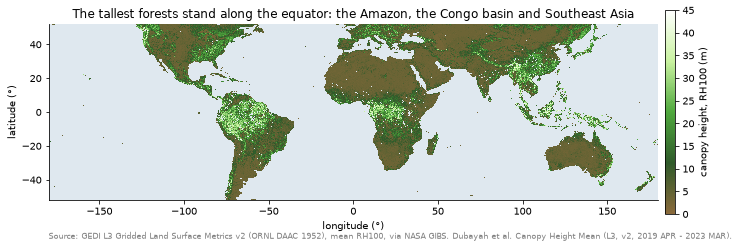

In [6]:
LAYER = "GEDI_ISS_L3_Canopy_Height_Mean_RH100_201904-202303"
BBOX = (-52, -180, 52, 180)
RES = 0.05
H, LATS, LONS = gibs_height(LAYER, BBOX, int(360 / RES), int(104 / RES))
layer_meta = json.loads(download(f"gibs/{LAYER}.json", GIBS_LAYER_META.format(layer=LAYER)).read_text())

forest_cmap = LinearSegmentedColormap.from_list("forest", ["#8a6a3b", "#2f5a2a", "#4fa83d", "#c9f2a0", "#ffffff"])
fig, ax = plt.subplots(figsize=(13, 4.6))
im = ax.imshow(H, extent=(-180, 180, -52, 52), cmap=forest_cmap, vmin=0, vmax=45, interpolation="nearest")
ax.set_facecolor("#dfe8ef")
ax.set(title="The tallest forests stand along the equator: the Amazon, the Congo basin and Southeast Asia",
       xlabel="longitude (°)", ylabel="latitude (°)")
fig.colorbar(im, ax=ax, label="canopy height, RH100 (m)", shrink=0.8, pad=0.01)
source_note(ax, f"{HEIGHT_CREDIT} {layer_meta['title']}.", y=-0.22)

### 3.3 How tall

Shares of the observed cells, and the regions the album could play. The regions are ours: the three great tropical forests, and the two US old-growth examples of 5095 (Northwest and East), as boxes around them.

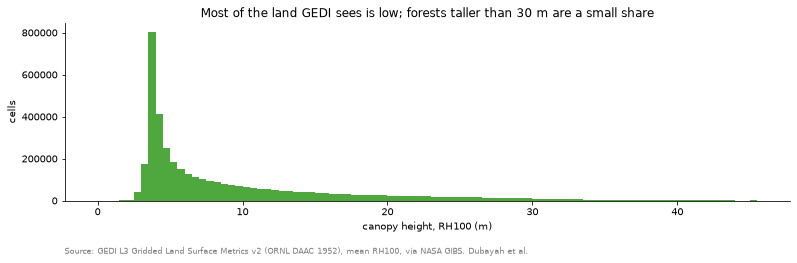

,share of observed cells (%)
under 5 m,42.3
5–10 m,27.1
10–20 m,20.0
20–30 m,8.4
30–45 m,2.2
45 m and above,0.1


,region,observed cells,median (m),90th percentile (m),taller than 30 m (%)
0,Amazon,184999,22.2,31.2,14.1
1,Congo basin,68926,22.2,32.2,16.1
2,Borneo,22297,19.8,38.2,24.6
3,US Pacific Northwest (5095),11689,18.2,34.8,16.9
4,Eastern US (5095),24857,16.8,26.2,2.7


In [7]:
observed = H[~np.isnan(H)]
bands = pd.cut(observed, [0, 5, 10, 20, 30, 45, np.inf], right=False,
               labels=["under 5 m", "5–10 m", "10–20 m", "20–30 m", "30–45 m", "45 m and above"])
share = (pd.Series(bands).value_counts(sort=False) / len(observed) * 100).round(1).rename("share of observed cells (%)")

REGIONS = {  # (south, west, north, east), ours
    "Amazon": (-15, -75, 5, -50),
    "Congo basin": (-5, 12, 5, 30),
    "Borneo": (-4, 108, 7, 119),
    "US Pacific Northwest (5095)": (42, -124.5, 49, -120),
    "Eastern US (5095)": (35, -85, 42, -76),
}


def box(bbox):
    s, w, n, e = bbox
    return H[np.ix_((LATS >= s) & (LATS <= n), (LONS >= w) & (LONS <= e))]


region_table = pd.DataFrame([{
    "region": name,
    "observed cells": int((~np.isnan(box(b))).sum()),
    "median (m)": np.nanmedian(box(b)),
    "90th percentile (m)": np.nanpercentile(box(b), 90),
    "taller than 30 m (%)": np.nanmean(box(b)[~np.isnan(box(b))] >= 30) * 100,
} for name, b in REGIONS.items()]).round(1)

fig, ax = plt.subplots(figsize=(13, 3.2))
ax.hist(observed, bins=np.arange(0, 46, 0.5), color="#4fa83d")
ax.set(xlabel="canopy height, RH100 (m)", ylabel="cells",
       title="Most of the land GEDI sees is low; forests taller than 30 m are a small share")
source_note(ax, HEIGHT_CREDIT, y=-0.3)
plt.show()
display(share.to_frame())
display(region_table)

### 3.4 Coverage filling in

> "Data is drawn on the globe over time, depicting how data coverage increases with each satellite pass." (4950)

GIBS keeps five cumulative composites, each from April 2019 to a later month. They show the grid filling in, not the forest changing: a cell, once seen, keeps its mean.

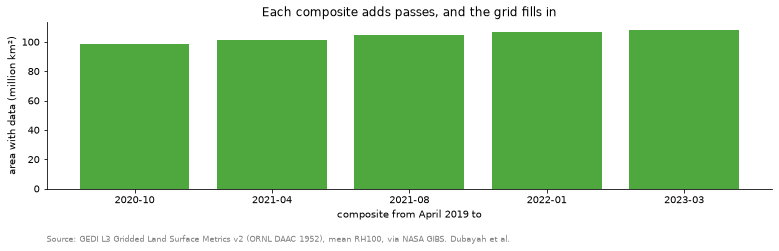

,until,observed cells,observed area (million km²)
0,2020-10,927057,98.2
1,2021-04,956172,101.6
2,2021-08,984441,104.8
3,2022-01,999174,106.5
4,2023-03,1011477,107.9


In [8]:
COMPOSITES = {  # layer suffix: last month of the composite
    "201904-202010": "2020-10", "201904-202104": "2021-04", "201904-202108": "2021-08",
    "201904-202201": "2022-01", "201904-202303": "2023-03"}
COARSE = 0.1
coverage = []
for suffix, until in COMPOSITES.items():
    h, lats, _ = gibs_height(f"GEDI_ISS_L3_Canopy_Height_Mean_RH100_{suffix}", BBOX, int(360 / COARSE), int(104 / COARSE))
    land_like = ~np.isnan(h)
    weight = np.cos(np.radians(lats))[:, None]
    coverage.append({"until": until, "observed cells": int(land_like.sum()),
                     "observed area (million km²)": float((land_like * weight).sum() * (111.32 * COARSE) ** 2 / 1e6)})
coverage = pd.DataFrame(coverage)

fig, ax = plt.subplots(figsize=(13, 3))
ax.bar(coverage["until"], coverage["observed area (million km²)"], color="#4fa83d")
ax.set(ylabel="area with data (million km²)", xlabel="composite from April 2019 to",
       title="Each composite adds passes, and the grid fills in")
source_note(ax, HEIGHT_CREDIT, y=-0.32)
plt.show()
display(coverage.round(1))

## 4. Along the orbit (ours)

GEDI reads the forest along the ground track of the ISS, a sine-shaped path between 51.6° N and 51.6° S. Read along one orbit, canopy height becomes a line that rises over forest, falls over grass and desert, and stops over the ocean: a melody with rests. This section is ours; EIC shows the passes being drawn but not one orbit as a profile.

The track is computed for a circular orbit of 51.64° inclination and 92.9 minutes, on a turning Earth. Its ascending node is placed where the orbit crosses the most tall forest, found by trying every whole degree.

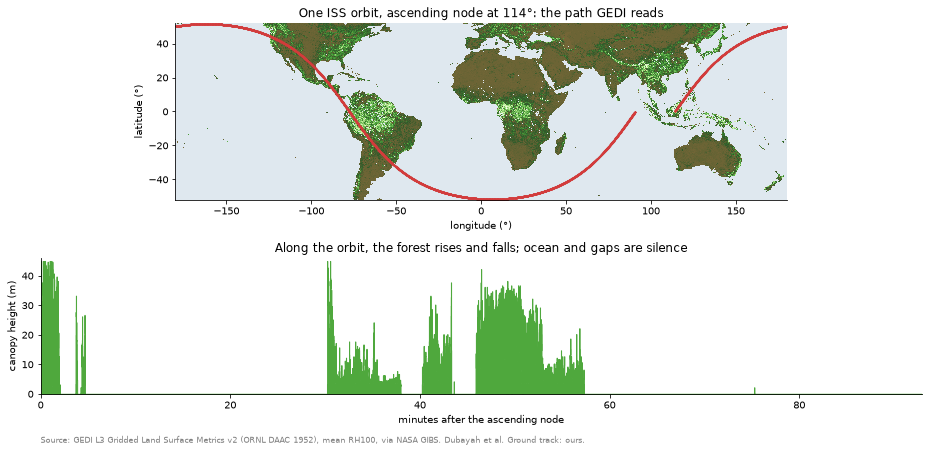

- Samples along the orbit: **7200** (one every 0.77 s of flight, about 5.6 km)
- With data: **25%**; no data (ocean, ice, gaps): 75%
- Taller than 30 m: **3.1%** of the samples

In [9]:
INCLINATION = np.radians(51.64)
PERIOD_S = 92.9 * 60
EARTH_TURN_DEG_S = 360 / 86164.1


def ground_track(node_lon, samples=7200):
    """Latitude, longitude and minute of one orbit starting at the ascending node."""
    t = np.linspace(0, PERIOD_S, samples, endpoint=False)
    u = 2 * np.pi * t / PERIOD_S
    lat = np.degrees(np.arcsin(np.sin(INCLINATION) * np.sin(u)))
    lon = node_lon + np.degrees(np.arctan2(np.cos(INCLINATION) * np.sin(u), np.cos(u))) - EARTH_TURN_DEG_S * t
    return lat, (lon + 180) % 360 - 180, t / 60


def heights_along(lat, lon):
    rows = np.clip(((BBOX[2] - lat) / RES).astype(int), 0, H.shape[0] - 1)
    cols = np.clip(((lon - BBOX[1]) / RES).astype(int), 0, H.shape[1] - 1)
    return H[rows, cols]


tall_forest = {node: np.nansum(heights_along(*ground_track(node)[:2]) >= 30) for node in range(-180, 180)}
NODE = max(tall_forest, key=tall_forest.get)
lat, lon, minute = ground_track(NODE)
orbit = pd.DataFrame({"minute": minute, "lat_deg": lat, "lon_deg": lon, "height_m": heights_along(lat, lon)})

fig, (top, bottom) = plt.subplots(2, 1, figsize=(13, 6.4), gridspec_kw={"height_ratios": [1.3, 1]})
top.imshow(H, extent=(-180, 180, -52, 52), cmap=forest_cmap, vmin=0, vmax=45, interpolation="nearest")
top.set_facecolor("#dfe8ef")
top.scatter(orbit["lon_deg"], orbit["lat_deg"], s=0.4, color="#d23c3c")
top.set(title=f"One ISS orbit, ascending node at {NODE}°: the path GEDI reads", xlabel="longitude (°)", ylabel="latitude (°)")
bottom.fill_between(orbit["minute"], orbit["height_m"].fillna(0), color="#4fa83d", step="mid")
bottom.set(xlim=(0, PERIOD_S / 60), ylim=(0, 46), xlabel="minutes after the ascending node", ylabel="canopy height (m)",
           title="Along the orbit, the forest rises and falls; ocean and gaps are silence")
source_note(bottom, f"{HEIGHT_CREDIT} Ground track: ours.", y=-0.36)
plt.tight_layout()
plt.show()

display(Markdown(
    f"- Samples along the orbit: **{len(orbit)}** (one every {PERIOD_S / len(orbit):.2f} s of flight, about 5.6 km)\n"
    f"- With data: **{orbit['height_m'].notna().mean() * 100:.0f}%**; no data (ocean, ice, gaps): {orbit['height_m'].isna().mean() * 100:.0f}%\n"
    f"- Taller than 30 m: **{(orbit['height_m'] >= 30).mean() * 100:.1f}%** of the samples"))

## 5. Carbon dioxide: GEOS

[5115](https://svs.gsfc.nasa.gov/5115/) · [5110](https://svs.gsfc.nasa.gov/5110/) · [GMAO datashare](https://portal.nccs.nasa.gov/datashare/gmao/geos_carb/carbon/vPRE/netcdf/ghg_tavg_day_glo_L1440x721_slv/)

> "Carbon dioxide (CO2) is the most prevalent greenhouse gas driving global climate change. However, its increase in the atmosphere would be even more rapid without land and ocean carbon sinks, which collectively absorb about half of human emissions every year." (5110)

- **What it is**: `XCO2`, the CO₂ dry-air column average: the share of CO₂ in the whole column of air, from the ground to the top of the atmosphere. GEOS assimilates satellite (OCO-2) and other observations into a model.
- **Provider**: NASA Global Modeling and Assimilation Office (GMAO). **Version**: PRE (from the file attributes).
- **Units**: mol mol⁻¹ in the files, shown as ppm (× 10⁶). **Grid**: 0.25°, global, daily.
- **Read here**: the 15th of every month, averaged over the globe by area (each latitude weighted by the cosine).

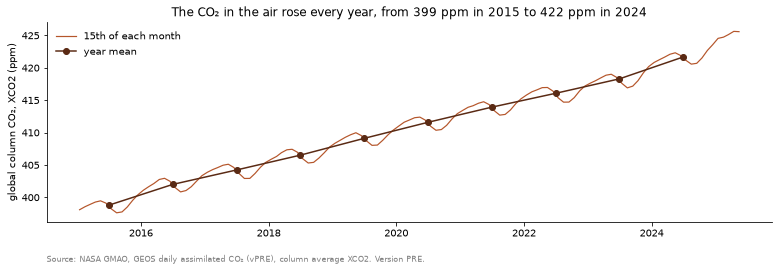

,xco2_ppm,months,rise_ppm
year,,,
2015,398.78,12,NaN
2016,401.99,12,3.21
2017,404.22,12,2.23
2018,406.51,12,2.29
2019,409.10,12,2.59
2020,411.58,12,2.48
2021,413.92,12,2.34
2022,416.06,12,2.14
2023,418.29,12,2.23


- Files read: **125** (2015-01-15 to 2025-05-15), version **PRE**
- Mean rise: **2.54 ppm a year**; the seasonal swing is about 2.5 ppm within a year
- EIC states no ppm figure on these pages, so there is no number to check against. The half absorbed by land and ocean (5110) cannot be computed from this file, which holds the concentration only.

In [10]:
def listing(url):
    text = requests.get(url + "/", timeout=60).text
    return sorted(set(re.findall(r'href="([^"?/][^"/]*)/?"', text)))


def geos_file(day):
    name = f"geos_carbon_vPRE.ghg_tavg_day_glo_L1440x721_slv.{day:%Y%m%d}.nc4"
    return download(f"geos/{name}", f"{GEOS_ROOT}/{day:%Y}/{day:%m}/{name}")


years = [y for y in listing(GEOS_ROOT) if y.isdigit()]
last_month = max(f"{years[-1]}-{m}" for m in listing(f"{GEOS_ROOT}/{years[-1]}") if m.isdigit())
days = [d + pd.Timedelta(days=14) for d in pd.date_range(f"{years[0]}-01-01", f"{last_month}-01", freq="MS")]

rows = []
for day in days:
    with h5py.File(geos_file(day)) as f:
        xco2 = f["XCO2"][0].astype(float)
        weight = np.cos(np.radians(f["lat"][:]))[:, None] * np.ones_like(xco2)
        version = f.attrs["VersionID"].decode()
    rows.append({"date": day, "xco2_ppm": float((xco2 * weight).sum() / weight.sum() * 1e6)})
co2 = pd.DataFrame(rows)
co2["year"] = co2["date"].dt.year
annual = co2.groupby("year")["xco2_ppm"].agg(["mean", "count"]).rename(columns={"mean": "xco2_ppm", "count": "months"})
annual = annual[annual["months"] == 12]
annual["rise_ppm"] = annual["xco2_ppm"].diff()

fig, ax = plt.subplots(figsize=(13, 3.6))
ax.plot(co2["date"], co2["xco2_ppm"], color="#b5562b", lw=1.2, label="15th of each month")
ax.plot(pd.to_datetime(annual.index.astype(str) + "-07-01"), annual["xco2_ppm"], "o-", color="#5a2a14", label="year mean")
ax.set(ylabel="global column CO₂, XCO2 (ppm)",
       title=f"The CO₂ in the air rose every year, from {annual['xco2_ppm'].iloc[0]:.0f} ppm in {annual.index[0]} "
             f"to {annual['xco2_ppm'].iloc[-1]:.0f} ppm in {annual.index[-1]}")
ax.legend(frameon=False)
source_note(ax, f"{CO2_CREDIT} Version {version}.", y=-0.2)
plt.show()
display(annual.round(2))
display(Markdown(
    f"- Files read: **{len(co2)}** ({co2['date'].min():%Y-%m-%d} to {co2['date'].max():%Y-%m-%d}), version **{version}**\n"
    f"- Mean rise: **{annual['rise_ppm'].mean():.2f} ppm a year**; the seasonal swing is about "
    f"{(co2.groupby('year')['xco2_ppm'].agg(lambda s: s.max() - s.min())).median():.1f} ppm within a year\n"
    "- EIC states no ppm figure on these pages, so there is no number to check against. The half absorbed by land and ocean "
    "(5110) cannot be computed from this file, which holds the concentration only."))

## 6. Message summary

In [11]:
display(Markdown("\n".join([
    "| EIC page | Message (quoted) | Key number (ours, from the data) | Series |",
    "| --- | --- | --- | --- |",
    f"| [14696](https://svs.gsfc.nasa.gov/14696/) | \"Trees consume this carbon dioxide. They eat it as food and they store it as wood.\" | — | — |",
    f"| [4950](https://svs.gsfc.nasa.gov/4950/), [5095](https://svs.gsfc.nasa.gov/5095/) | \"Bright green and white represent taller vegetation.\" | "
    f"{share.iloc[-2:].sum():.1f}% of observed cells are 30 m or taller; Amazon median {region_table.set_index('region').loc['Amazon', 'median (m)']:.0f} m | canopy height grid, orbit profile |",
    f"| [5110](https://svs.gsfc.nasa.gov/5110/), [5115](https://svs.gsfc.nasa.gov/5115/) | \"... land and ocean carbon sinks, which collectively absorb about half of human emissions every year.\" | "
    f"+{annual['rise_ppm'].mean():.2f} ppm a year, {annual.index[0]}–{annual.index[-1]} | global XCO2, monthly and yearly |",
])))

| EIC page | Message (quoted) | Key number (ours, from the data) | Series |
| --- | --- | --- | --- |
| [14696](https://svs.gsfc.nasa.gov/14696/) | "Trees consume this carbon dioxide. They eat it as food and they store it as wood." | — | — |
| [4950](https://svs.gsfc.nasa.gov/4950/), [5095](https://svs.gsfc.nasa.gov/5095/) | "Bright green and white represent taller vegetation." | 2.3% of observed cells are 30 m or taller; Amazon median 22 m | canopy height grid, orbit profile |
| [5110](https://svs.gsfc.nasa.gov/5110/), [5115](https://svs.gsfc.nasa.gov/5115/) | "... land and ocean carbon sinks, which collectively absorb about half of human emissions every year." | +2.54 ppm a year, 2015–2024 | global XCO2, monthly and yearly |

## 7. Track candidates

The series on offer. Section 8 exports the ones the album plays.

In [12]:
display(pd.DataFrame([
    {"series": "Canopy height along one orbit (section 4)", "length": f"{len(orbit)} samples, {PERIOD_S / 60:.1f} min of flight",
     "range": f"{np.nanmin(orbit['height_m']):.1f}–{np.nanmax(orbit['height_m']):.0f} m, {orbit['height_m'].isna().mean() * 100:.0f}% rests",
     "resolution": "about 5.6 km, 0.5 m classes", "could play": "melody: height to pitch, gaps to rests"},
    {"series": "Canopy height in a region (section 3.3)", "length": "one grid per region",
     "range": "0–45 m and above", "resolution": "1 km cells, 0.5 m classes", "could play": "a scanner across the region, as on the glacier album"},
    {"series": "Coverage filling in (section 3.4)", "length": f"{len(coverage)} composites",
     "range": f"{coverage['observed area (million km²)'].min():.0f}–{coverage['observed area (million km²)'].max():.0f} million km²",
     "resolution": "2020-10 to 2023-03", "could play": "the globe being drawn pass by pass"},
    {"series": "Global XCO2 (section 5)", "length": f"{len(co2)} months, {len(annual)} full years",
     "range": f"{co2['xco2_ppm'].min():.0f}–{co2['xco2_ppm'].max():.0f} ppm", "resolution": "monthly (15th), yearly mean",
     "could play": "the time axis: one year a bar, rising underneath"},
]))

,series,length,range,resolution,could play
0,Canopy height along one orbit (section 4),"7200 samples, 92.9 min of flight","2.2–45 m, 75% rests","about 5.6 km, 0.5 m classes","melody: height to pitch, gaps to rests"
1,Canopy height in a region (section 3.3),one grid per region,0–45 m and above,"1 km cells, 0.5 m classes","a scanner across the region, as on the glacier album"
2,Coverage filling in (section 3.4),5 composites,98–108 million km²,2020-10 to 2023-03,the globe being drawn pass by pass
3,Global XCO2 (section 5),"125 months, 10 full years",398–426 ppm,"monthly (15th), yearly mean","the time axis: one year a bar, rising underneath"


## 8. Track export

The album plays four tracks (our choice): one ISS orbit over each of the three great tropical forests and over the Pacific Northwest, the old-growth example of 5095. Every track runs through the same CO₂ months, so each one ends with the air thicker than it began.

**Time.** A step is a sixteenth note of 0.22 s; two steps make a month of CO₂, so the 125 months take 250 steps, 55 s. The orbit is laid over the same 250 steps: it starts in the middle of its longest stretch without data (over the sea), and the sea goes by four times as fast as the land, so most of the track is forest (ours).

**Orbit.** For each track, the ascending node (to 0.5°) whose orbit crosses the most canopy of 10 m or taller inside the track's region (section 3.3). Each step keeps where the orbit is at its start, and the mean height and its standard deviation under it when at least half of its samples have data.

**Forest drawn on the globe.** The 0.25° cells (the mean of the 0.05° grid in each, where at least half has data) within 1.5° of the orbit with canopy of 5 m or taller, each with the step at which the orbit first passes it. The real GEDI swath (about 4 km) would not show on the record label; this band is drawn for sight (ours).

**Forest density.** For each step, the share of the 0.25° cells with data within 1.5° of its samples (the band drawn on the globe) whose canopy is 10 m or taller: how thickly the columns stand around the ISS. GEDI's canopy cover (L2B) needs a login and GIBS has no layer of it, so density is read from the same RH100 grid, as the colours of 4950 crowd together (ours).

**Height spread.** The GIBS layer of the RH100 standard deviation in each 1 km cell (same L3 product, its own colour table): how uneven the canopy is.

In [13]:
TRACKS = Path("../data/forest/tracks")
TRACKS.mkdir(parents=True, exist_ok=True)
STEP_SEC = 0.22
STEPS_PER_MONTH = 2
STEPS = STEPS_PER_MONTH * len(co2)
SEA_SPEEDUP = 4
CELL = 0.25
BAND_DEG = 1.5
DRAWN_FROM_M = 5
DENSE_FROM_M = 10
SD_LAYER = "GEDI_ISS_L3_Canopy_Height_StdDev_RH100_201904-202303"
SD_COLORMAP = "https://gibs.earthdata.nasa.gov/colormaps/v1.3/GEDI_RH100_Stddev_Color_Index.xml"
SD, _, _ = gibs_grid(SD_LAYER, BBOX, int(360 / RES), int(104 / RES), colour_table(SD_COLORMAP))


def grid_at(grid, lat, lon):
    rows = np.clip(((BBOX[2] - np.asarray(lat)) / RES).astype(int), 0, grid.shape[0] - 1)
    cols = np.clip(((np.asarray(lon) - BBOX[1]) / RES).astype(int), 0, grid.shape[1] - 1)
    return grid[rows, cols]


TRACK_REGIONS = {  # title: region of section 3.3
    "Amazon": "Amazon",
    "Congo Basin": "Congo basin",
    "Borneo": "Borneo",
    "Pacific Northwest": "US Pacific Northwest (5095)",
}


def best_node(region):
    s, w, n, e = REGIONS[region]
    def score(node):
        lat, lon, _ = ground_track(node)
        inside = (lat >= s) & (lat <= n) & (lon >= w) & (lon <= e)
        return np.nansum(heights_along(lat, lon)[inside] >= 10)
    return max(np.arange(-180, 180, 0.5), key=score)


def orbit_steps(node):
    lat, lon, _ = ground_track(node)
    h = heights_along(lat, lon)
    gap = np.isnan(h)
    # Start in the middle of the longest run without data, going round the orbit's end.
    runs, start = [], None
    doubled = np.concatenate([gap, gap])
    for i, g in enumerate(doubled):
        if g and start is None:
            start = i
        if (not g or i == len(doubled) - 1) and start is not None:
            runs.append((i - start, start))
            start = None
    length, first = max(r for r in runs if r[1] < len(gap))
    shift = (first + length // 2) % len(gap)
    lat, lon, h = (np.roll(a, -shift) for a in (lat, lon, h))
    sd = grid_at(SD, lat, lon)
    weight = np.where(np.isnan(h), 1 / SEA_SPEEDUP, 1.0)
    step = np.minimum((np.cumsum(weight) - weight) / weight.sum() * STEPS, STEPS - 1).astype(int)
    rows = []
    for s in range(STEPS):
        at = np.flatnonzero(step == s)
        around = np.array([H_CELL[k] for k in band_cells(lat[at], lon[at])]) if len(at) else np.array([])
        around = around[~np.isnan(around)]
        first_i = at[0] if len(at) else rows[-1]["i"]
        land = np.mean(~np.isnan(h[at])) if len(at) else 0.0
        rows.append({"i": first_i, "step": s, "lat_deg": lat[first_i], "lon_deg": lon[first_i],
                     "height_m": np.nanmean(h[at]) if land >= 0.5 else np.nan,
                     "height_sd_m": np.nanmean(sd[at]) if land >= 0.5 and np.any(~np.isnan(sd[at])) else np.nan,
                     "land_share": land,
                     "forest_share": np.mean(around >= DENSE_FROM_M) if len(around) else np.nan})
    return pd.DataFrame(rows).drop(columns="i"), lat, lon, step


BLOCK = round(CELL / RES)
_blocks = H.reshape(H.shape[0] // BLOCK, BLOCK, H.shape[1] // BLOCK, BLOCK)
_have = (~np.isnan(_blocks)).mean(axis=(1, 3))
with np.errstate(invalid="ignore"):
    H_CELL = np.where(_have >= 0.5, np.nanmean(_blocks, axis=(1, 3)), np.nan)


def band_cells(lat, lon):
    """The (row, col) of every CELL cell within BAND_DEG of the given points."""
    keys = set()
    offsets = np.arange(-BAND_DEG, BAND_DEG + 1e-9, CELL / 2)
    for la, lo in zip(lat, lon):
        for dla in offsets:
            row = int((BBOX[2] - (la + dla)) // CELL)
            if 0 <= row < H_CELL.shape[0]:
                keys.update((row, int((((lo + dlo) + 180) % 360) // CELL)) for dlo in offsets)
    return keys


def drawn_cells(lat, lon, step):
    """The CELL cells within BAND_DEG of the orbit with canopy of DRAWN_FROM_M or more, with the step the orbit first
    passes each."""
    first = {}
    offsets = np.arange(-BAND_DEG, BAND_DEG + 1e-9, CELL / 2)
    for la, lo, s in zip(lat, lon, step):
        for dla in offsets:
            row = int((BBOX[2] - (la + dla)) // CELL)
            if not 0 <= row < H_CELL.shape[0]:
                continue
            for dlo in offsets:
                col = int((((lo + dlo) + 180) % 360) // CELL)
                first.setdefault((row, col), s)
    keys = np.array(list(first))
    cells = pd.DataFrame({"lat_deg": BBOX[2] - (keys[:, 0] + 0.5) * CELL, "lon_deg": -180 + (keys[:, 1] + 0.5) * CELL,
                          "step": list(first.values()), "height_m": H_CELL[keys[:, 0], keys[:, 1]]})
    cells = cells[cells["height_m"] >= DRAWN_FROM_M]
    return cells.sort_values(["step", "lat_deg", "lon_deg"])[["step", "lat_deg", "lon_deg", "height_m"]]


def slug(text):
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")


exports = {}
for title, region in TRACK_REGIONS.items():
    node = best_node(region)
    steps, lat, lon, step = orbit_steps(node)
    exports[title] = {"node": node, "steps": steps, "cells": drawn_cells(lat, lon, step), "region": region}

display(pd.DataFrame([{
    "track": t, "ascending node (°)": e["node"], "steps with forest ≥ 5 m": int((e["steps"]["height_m"] >= 5).sum()),
    "steps over the sea or gaps": int(e["steps"]["height_m"].isna().sum()),
    "tallest step (m)": round(e["steps"]["height_m"].max(), 1), "cells drawn": len(e["cells"]),
    "forest density, median of forest steps": round(e["steps"].loc[e["steps"]["height_m"] >= 5, "forest_share"].median(), 2),
} for t, e in exports.items()]))

/var/folders/rh/n9cfpbn12t33ns36vscsv71h0000gn/T/ipykernel_72661/260651363.py:77: RuntimeWarning: Mean of empty slice
  H_CELL = np.where(_have >= 0.5, np.nanmean(_blocks, axis=(1, 3)), np.nan)


,track,ascending node (°),steps with forest ≥ 5 m,steps over the sea or gaps,tallest step (m),cells drawn,"forest density, median of forest steps"
0,Amazon,125.5,116,116,30.7,5417,0.61
1,Congo Basin,-149.5,111,83,30.4,5861,0.46
2,Borneo,112.5,113,112,33.7,5605,0.65
3,Pacific Northwest,-166.5,100,94,29.8,5045,0.12


The four orbits, and the heights the lead plays along each (one bar is 12 steps; the grey line is the CO₂ every track plays under them):

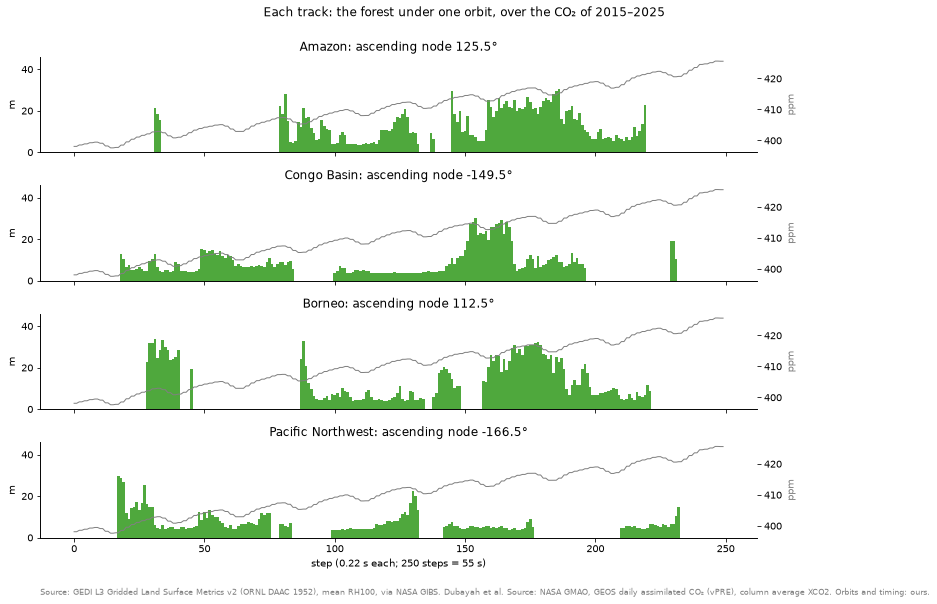

In [14]:
fig, axes = plt.subplots(len(exports), 1, figsize=(13, 2.1 * len(exports)), sharex=True)
for ax, (title, e) in zip(axes, exports.items()):
    s = e["steps"]
    ax.bar(s["step"], s["height_m"].fillna(0), width=1, color="#4fa83d")
    ax.set(ylim=(0, 46), ylabel="m", title=f"{title}: ascending node {e['node']}°")
    air = ax.twinx()
    air.plot(np.arange(STEPS), np.repeat(co2["xco2_ppm"].to_numpy(), STEPS_PER_MONTH), color="gray", lw=1)
    air.set_ylabel("ppm", color="gray")
    air.spines["top"].set_visible(False)
axes[-1].set_xlabel(f"step ({STEP_SEC} s each; {STEPS} steps = {STEPS * STEP_SEC:.0f} s)")
fig.suptitle("Each track: the forest under one orbit, over the CO₂ of 2015–2025", y=1.0)
source_note(axes[-1], f"{HEIGHT_CREDIT} {CO2_CREDIT} Orbits and timing: ours.", y=-0.6)
plt.tight_layout()
plt.show()

Export: per track, the orbit (`<track>_orbit.csv`) and the cells drawn on the globe (`<track>_forest.csv`); the CO₂ months all tracks share (`global_xco2_monthly.csv`); and `tracks.json` (see [data-guide.md](../docs/data-guide.md)).

In [15]:
for old in TRACKS.glob("*"):  # tracks/ is written only here
    old.unlink()
co2_file = "global_xco2_monthly.csv"
co2.assign(date=co2["date"].dt.strftime("%Y-%m-01")).round({"xco2_ppm": 3})[["date", "xco2_ppm"]].to_csv(TRACKS / co2_file, index=False)

today = date.today().isoformat()
quote = transcript[start:end]
height_source = {
    "source": "GEDI L3 Gridded Land Surface Metrics, Version 2 (ORNL DAAC 1952): mean RH100, through NASA GIBS",
    "sourceUrl": GEDI_L3_DOI,
    "downloadUrl": f"{GIBS_WMS}?SERVICE=WMS&VERSION=1.3.0&REQUEST=GetMap&LAYERS={LAYER}&CRS=EPSG:4326&BBOX=-52,-180,52,180&WIDTH=7200&HEIGHT=2080&FORMAT=image/png",
    "colormapUrl": GIBS_COLORMAP,
    "version": "2", "doi": GEDI_L3_DOI, "downloaded": today,
    "license": "NASA Earth science data: open, no restrictions",
    "credit": "Dubayah, R., et al. GEDI L3 Gridded Land Surface Metrics, Version 2. ORNL DAAC. Served by NASA GIBS.",
    "substitute": "EIC cites GEDI Relative Height (RH100) with a link to gedi.umd.edu. The footprint and GeoTIFF files need an Earthdata login, so the GEDI team's 1 km grid of RH100 is read from GIBS images, 0.5 m classes, 45 m and above as one.",
}
spread_source = {**height_source,
    "source": "GEDI L3 Gridded Land Surface Metrics, Version 2 (ORNL DAAC 1952): standard deviation of RH100, through NASA GIBS",
    "downloadUrl": height_source["downloadUrl"].replace(LAYER, SD_LAYER), "colormapUrl": SD_COLORMAP}
co2_source = {
    "source": "NASA GMAO GEOS daily assimilated CO₂, CH₄ and CO, 0.25° (vPRE): XCO2",
    "sourceUrl": GEOS_ROOT + "/",
    "downloadUrl": f"{GEOS_ROOT}/YYYY/MM/geos_carbon_vPRE.ghg_tavg_day_glo_L1440x721_slv.YYYYMM15.nc4",
    "version": version, "downloaded": today,
    "license": "NASA Earth science data: open, no restrictions",
    "credit": "NASA Global Modeling and Assimilation Office (GMAO), GEOS carbon (contact: Brad Weir)",
    "substitute": "EIC names GEOS Carbon Dioxide without a version or link; this is GMAO's public release, read on the 15th of each month.",
}
pages = [
    {"svsId": VIDEO_ID, "svsUrl": f"https://svs.gsfc.nasa.gov/{VIDEO_ID}/", "message": quote},
    {"svsId": 4950, "svsUrl": "https://svs.gsfc.nasa.gov/4950/",
     "message": "Brown and dark green represent shorter vegetation. Bright green and white represent taller vegetation."},
    {"svsId": 5110, "svsUrl": "https://svs.gsfc.nasa.gov/5110/",
     "message": plain(svs_page(5110)["description"]).split(" || ")[0].split(". Advanced")[0] + "."},
]
entries = []
for title, e in exports.items():
    orbit_file, cells_file = f"{slug(title)}_orbit.csv", f"{slug(title)}_forest.csv"
    e["steps"].round({"lat_deg": 3, "lon_deg": 3, "height_m": 1, "height_sd_m": 1, "land_share": 2, "forest_share": 2}).to_csv(TRACKS / orbit_file, index=False)
    e["cells"].round({"lat_deg": 3, "lon_deg": 3, "height_m": 1}).to_csv(TRACKS / cells_file, index=False)
    track_pages = pages + ([{"svsId": 5095, "svsUrl": "https://svs.gsfc.nasa.gov/5095/",
                             "message": plain(svs_page(5095)["media_groups"][0].get("caption"))}] if "5095" in e["region"] else [])
    entries.append({
        "file": orbit_file,
        "title": title,
        "pages": track_pages,
        "note": (f"Ours: one ISS orbit (51.64°, 92.9 min) with its ascending node at {e['node']}°, the one crossing the most "
                 f"canopy of 10 m or taller in the region {REGIONS[e['region']]} (south, west, north, east). {STEPS} steps of "
                 f"{STEP_SEC} s; the sea goes by {SEA_SPEEDUP} times as fast as the land. Two steps are a month of CO₂."),
        "sources": [height_source, spread_source, co2_source],
        "visuals": [cells_file, co2_file],
        "units": {"step": f"sixteenth note, {STEP_SEC} s", "lat_deg": "degrees north", "lon_deg": "degrees east",
                  "height_m": "m (RH100, mean of the step)", "height_sd_m": "m (standard deviation of RH100 in a 1 km cell)",
                  "land_share": "share of the step's samples with data",
                  "forest_share": "share of the 0.25° cells with data within 1.5° of the step whose canopy is 10 m or taller",
                  "xco2_ppm": "ppm (column average, global mean)"},
        "timeRange": [co2["date"].min().strftime("%Y-%m-01"), co2["date"].max().strftime("%Y-%m-01")],
    })
(TRACKS / "tracks.json").write_text(json.dumps(entries, indent=2, ensure_ascii=False) + "\n")
display(pd.DataFrame([{"file": p.name, "KB": round(p.stat().st_size / 1024, 1)} for p in sorted(TRACKS.iterdir())]))

,file,KB
0,amazon_forest.csv,125.4
1,amazon_orbit.csv,7.7
2,borneo_forest.csv,130.4
3,borneo_orbit.csv,7.8
4,congo_basin_forest.csv,130.0
5,congo_basin_orbit.csv,7.9
6,global_xco2_monthly.csv,2.3
7,pacific_northwest_forest.csv,113.0
8,pacific_northwest_orbit.csv,7.9
9,tracks.json,21.3
